# Circ1PAT1R Fisher matrix with the LISA response

Computes the Fisher matrix over all parameters of FEW's post-adiabatic model `Circ1PAT1R` (FEW >= 2.2), including the secondary spin `chi2`, through the LISA TDI response (A and E channels).

**Requirements:** `lisaanalysistools` 1.2.0 and `fastlisaresponse` 1.1.17 (see the installation guide).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import few
from few.waveform import Circ1PAT1R
from fastlisaresponse import ResponseWrapper
from lisatools.detector import EqualArmlengthOrbits
from lisatools.sensitivity import get_sensitivity, A1TDISens, E1TDISens

from stableemrifisher.fisher import StableEMRIFisher
from stableemrifisher.utils.plot import plot_covariance_ellipses

use_gpu = False  # set to True to run on an NVIDIA GPU
response_backend = "gpu" if use_gpu else "cpu"  # backend of the LISA response and orbits

if not use_gpu:
    # restrict FEW to its CPU backend
    cfg_set = few.get_config_setter(reset=True)
    cfg_set.enable_backends("cpu")

## Set up StableEMRIFisher

`evolve_primary=False` holds the primary's mass and spin fixed.

In [2]:
T = 0.1  # observation time, years
dt = 10.0  # sampling interval, seconds

ResponseWrapper_kwargs = dict(
    Tobs=T,
    dt=dt,
    index_lambda=8,  # position of phiS in the waveform arguments
    index_beta=7,  # position of qS in the waveform arguments
    t0=10000.0,  # seconds at each end of the signal where the response is unreliable
    remove_garbage="zero",  # zero the signal within t0 of each end
    flip_hx=True,  # FEW returns h+ - i hx
    is_ecliptic_latitude=False,  # qS is a polar angle, not a latitude
    orbits=EqualArmlengthOrbits(force_backend=response_backend),
    force_backend=response_backend,
    order=20,  # order of the Lagrange interpolation of the time delays
    tdi="1st generation",
    tdi_chan="AE",
)

channels = [A1TDISens, E1TDISens]

sef = StableEMRIFisher(
    waveform_class=Circ1PAT1R,
    waveform_class_kwargs=dict(
        inspiral_kwargs=dict(
            evolve_primary=False,  # hold the primary's mass and spin fixed
            err=1e-11,  # trajectory integrator tolerance
        ),
    ),
    waveform_kwargs=dict(mode_selection_threshold=1e-5),
    ResponseWrapper=ResponseWrapper,
    ResponseWrapper_kwargs=ResponseWrapper_kwargs,
    noise_model=get_sensitivity,
    noise_kwargs=[{"sens_fn": channel} for channel in channels],
    deriv_type="stable",
    use_gpu=use_gpu,
)

## Compute the Fisher matrix

The secondary spin `chi2` is passed through `add_param_args`.

Waveform Generated. SNR: 279.2715522900796
  m1         delta = 1.931e+01   relerr = 4.6e-11   (8 steps)             
  m2         delta = 1.931e-02   relerr = 1.9e-10   (8 steps)              
  a          delta = 3.355e-06   relerr = 9.9e-10   (8 steps)              
  p0         delta = 3.089e-04   relerr = 2.2e-10   (8 steps)              
  dist       analytic derivative                                           
  qS         delta = 5.179e-09   relerr = 6.8e-05   (8 steps)              
  phiS       delta = 5.179e-09   relerr = 6.0e-05   (8 steps)                
  qK         delta = 1.931e-05   relerr = 1.0e-11   (8 steps)                
  phiK       delta = 1.931e-05   relerr = 2.7e-12   (8 steps)                
  Phi_phi0   analytic derivative                                             
  chi2       delta = 3.541e-04   relerr = 1.1e-08   (8 steps)                
Choosing step sizes: 100%|██████████| 72/72 [00:30<00:00,  2.38deriv/s]      


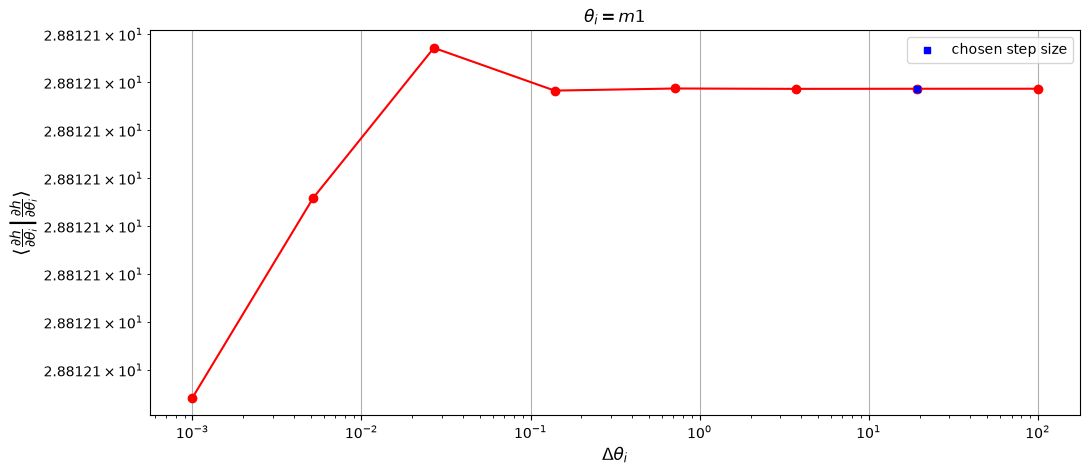

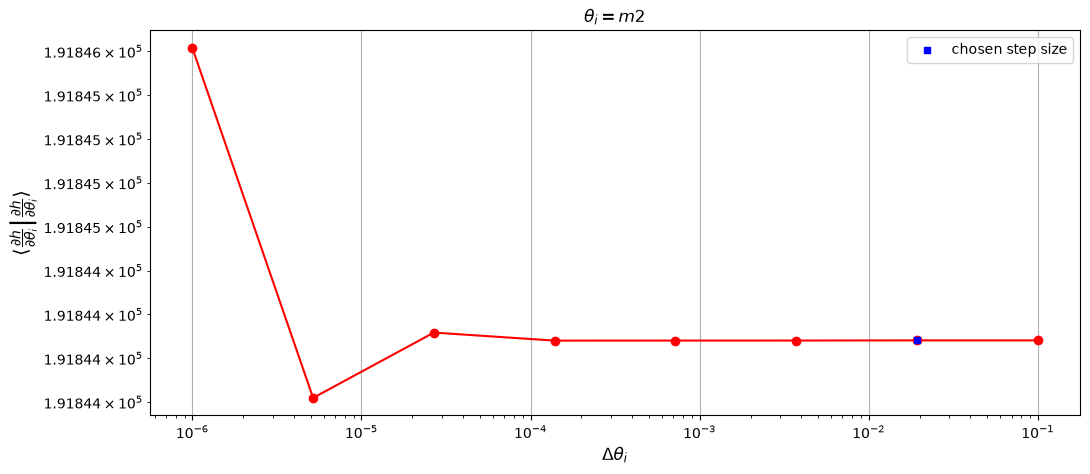

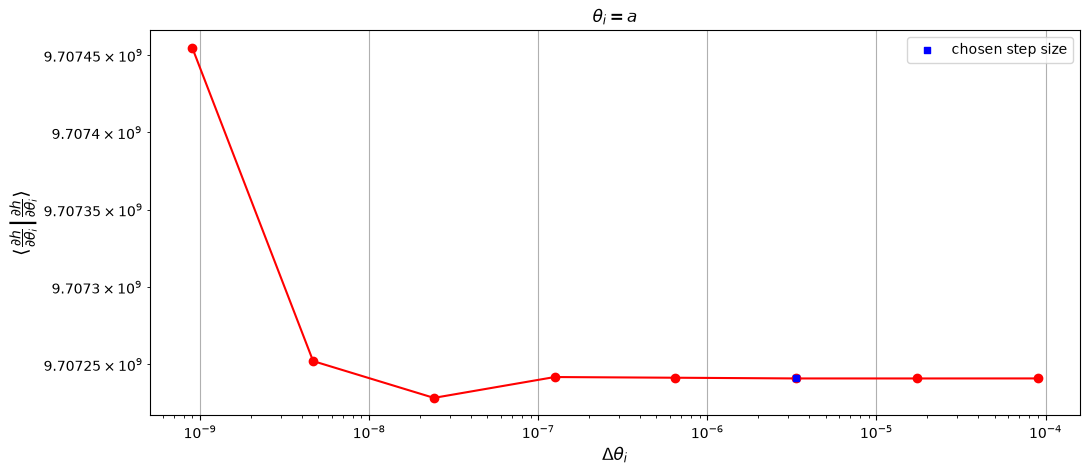

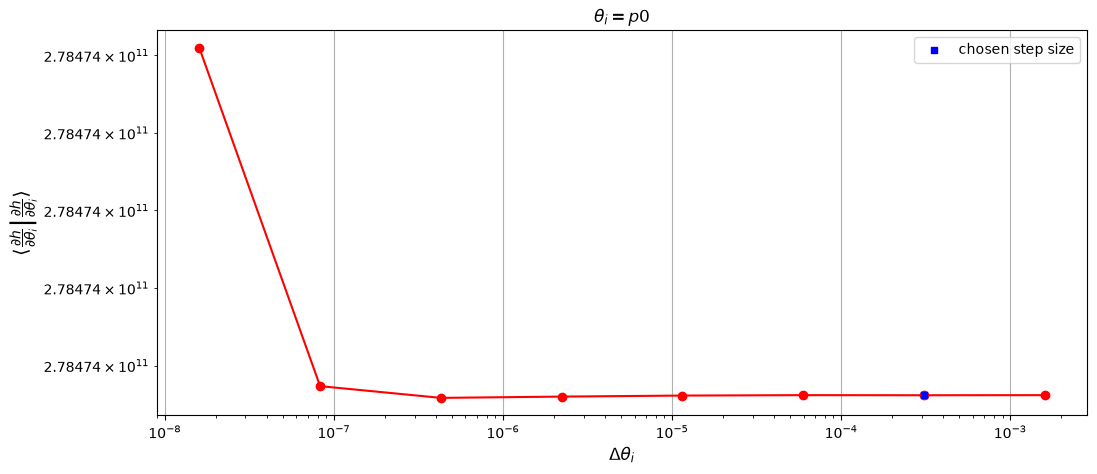

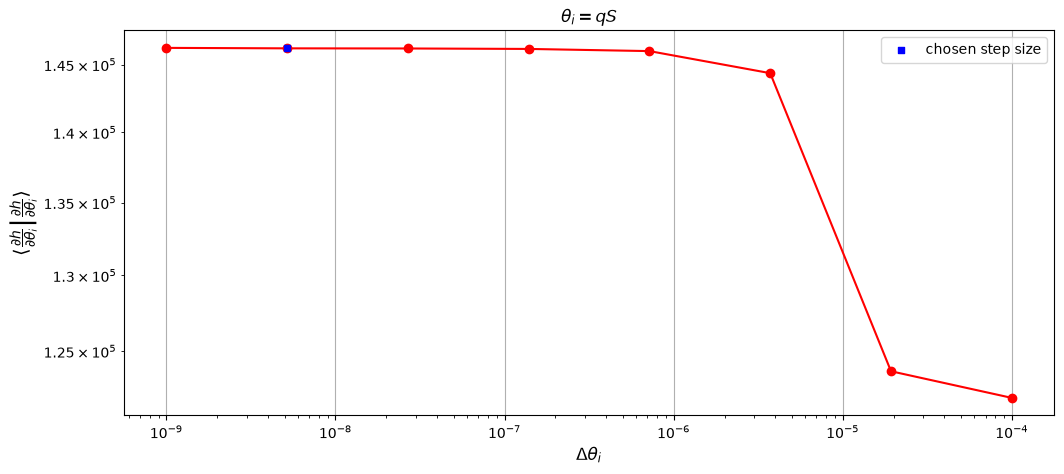

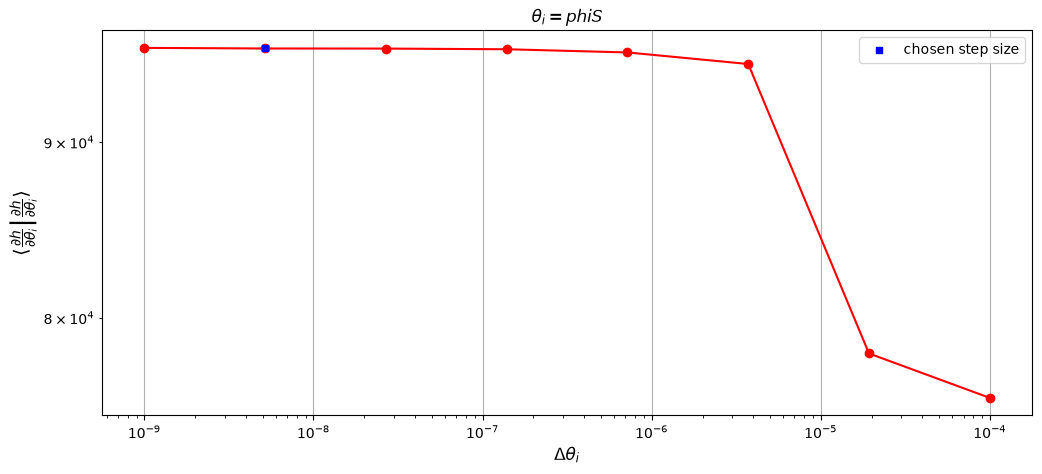

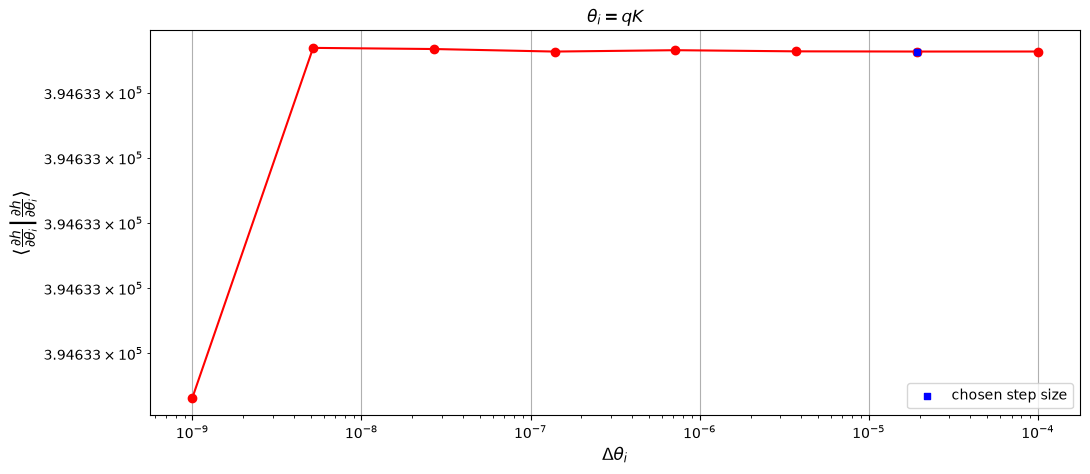

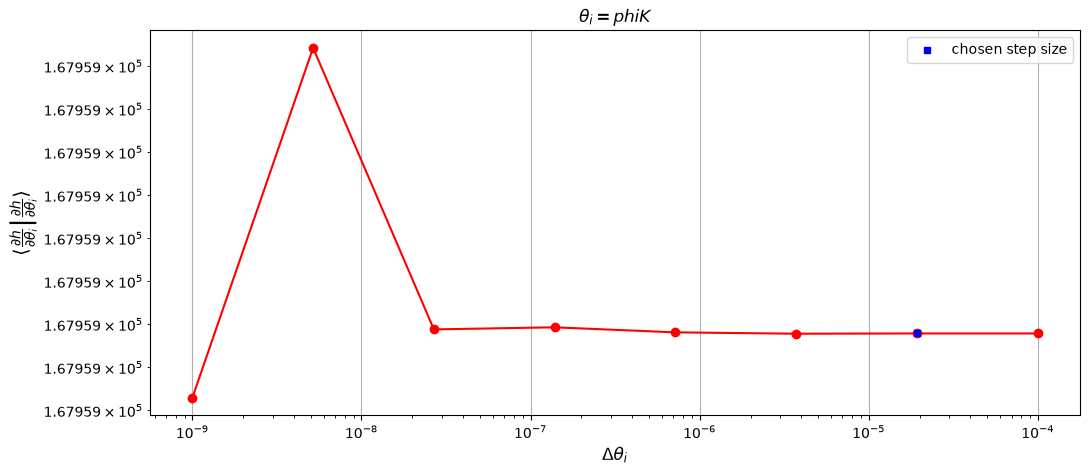

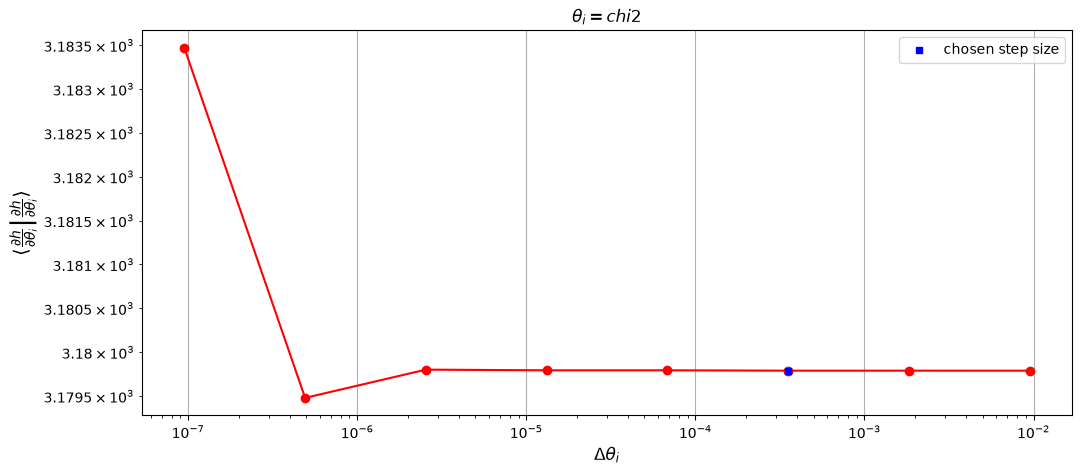

Computing Fisher   : 100%|██████████| 11/11 [00:04<00:00,  2.58deriv/s]          
Degenerate parameters: a combination of m1, p0 is unconstrained (relative eigenvalue 1.8e-14). The Fisher matrix is not invertible.


In [3]:
wave_params = dict(
    m1=1e6,  # primary mass, solar masses
    m2=1e3,  # secondary mass, solar masses
    a=0.9,  # primary spin
    p0=16.0,  # initial orbital separation
    e0=0.0,  # not used by Circ1PAT1R
    xI0=1.0,  # not used by Circ1PAT1R
    dist=1.0,  # luminosity distance, Gpc
    qS=np.pi / 3,  # sky location, polar angle
    phiS=np.pi / 4,  # sky location, azimuthal angle
    qK=np.pi / 6,  # spin orientation, polar angle
    phiK=np.pi / 8,  # spin orientation, azimuthal angle
    Phi_phi0=1.0,  # initial azimuthal phase
    Phi_theta0=0.0,  # not used by Circ1PAT1R
    Phi_r0=0.0,  # not used by Circ1PAT1R
)
add_param_args = dict(chi2=0.95)  # secondary spin

param_names = ["m1", "m2", "a", "p0", "dist", "qS", "phiS", "qK", "phiK", "Phi_phi0", "chi2"]

Ndelta = 8
# trial step sizes of the angles, from largest to smallest; default grids for the others
delta_range = {angle: np.geomspace(1e-4, 1e-9, Ndelta) for angle in ["qS", "phiS", "qK", "phiK"]}

Fisher = sef(
    wave_params,
    add_param_args=add_param_args,
    param_names=param_names,
    der_order=4,
    Ndelta=Ndelta,
    delta_range=delta_range,
    stability_plot=True,
    stats_for_nerds=True,
)

## Parameter uncertainties

In [4]:
covariance = np.linalg.inv(Fisher)
sigma = np.sqrt(np.diag(covariance))

for name, s in zip(param_names, sigma):
    print(f"{name:9s} = {sef.wave_params[name]:.6g} +/- {s:.3g}")

m1        = 1e+06 +/- 3.54e+05
m2        = 1000 +/- 235
a         = 0.9 +/- 0.283
p0        = 16 +/- 3.77
dist      = 1 +/- 0.0396
qS        = 1.0472 +/- 0.00467
phiS      = 0.785398 +/- 0.00479
qK        = 0.523599 +/- 0.0648
phiK      = 0.392699 +/- 0.0792
Phi_phi0  = 1 +/- 0.0366
chi2      = 0.95 +/- 526


## Covariance ellipses

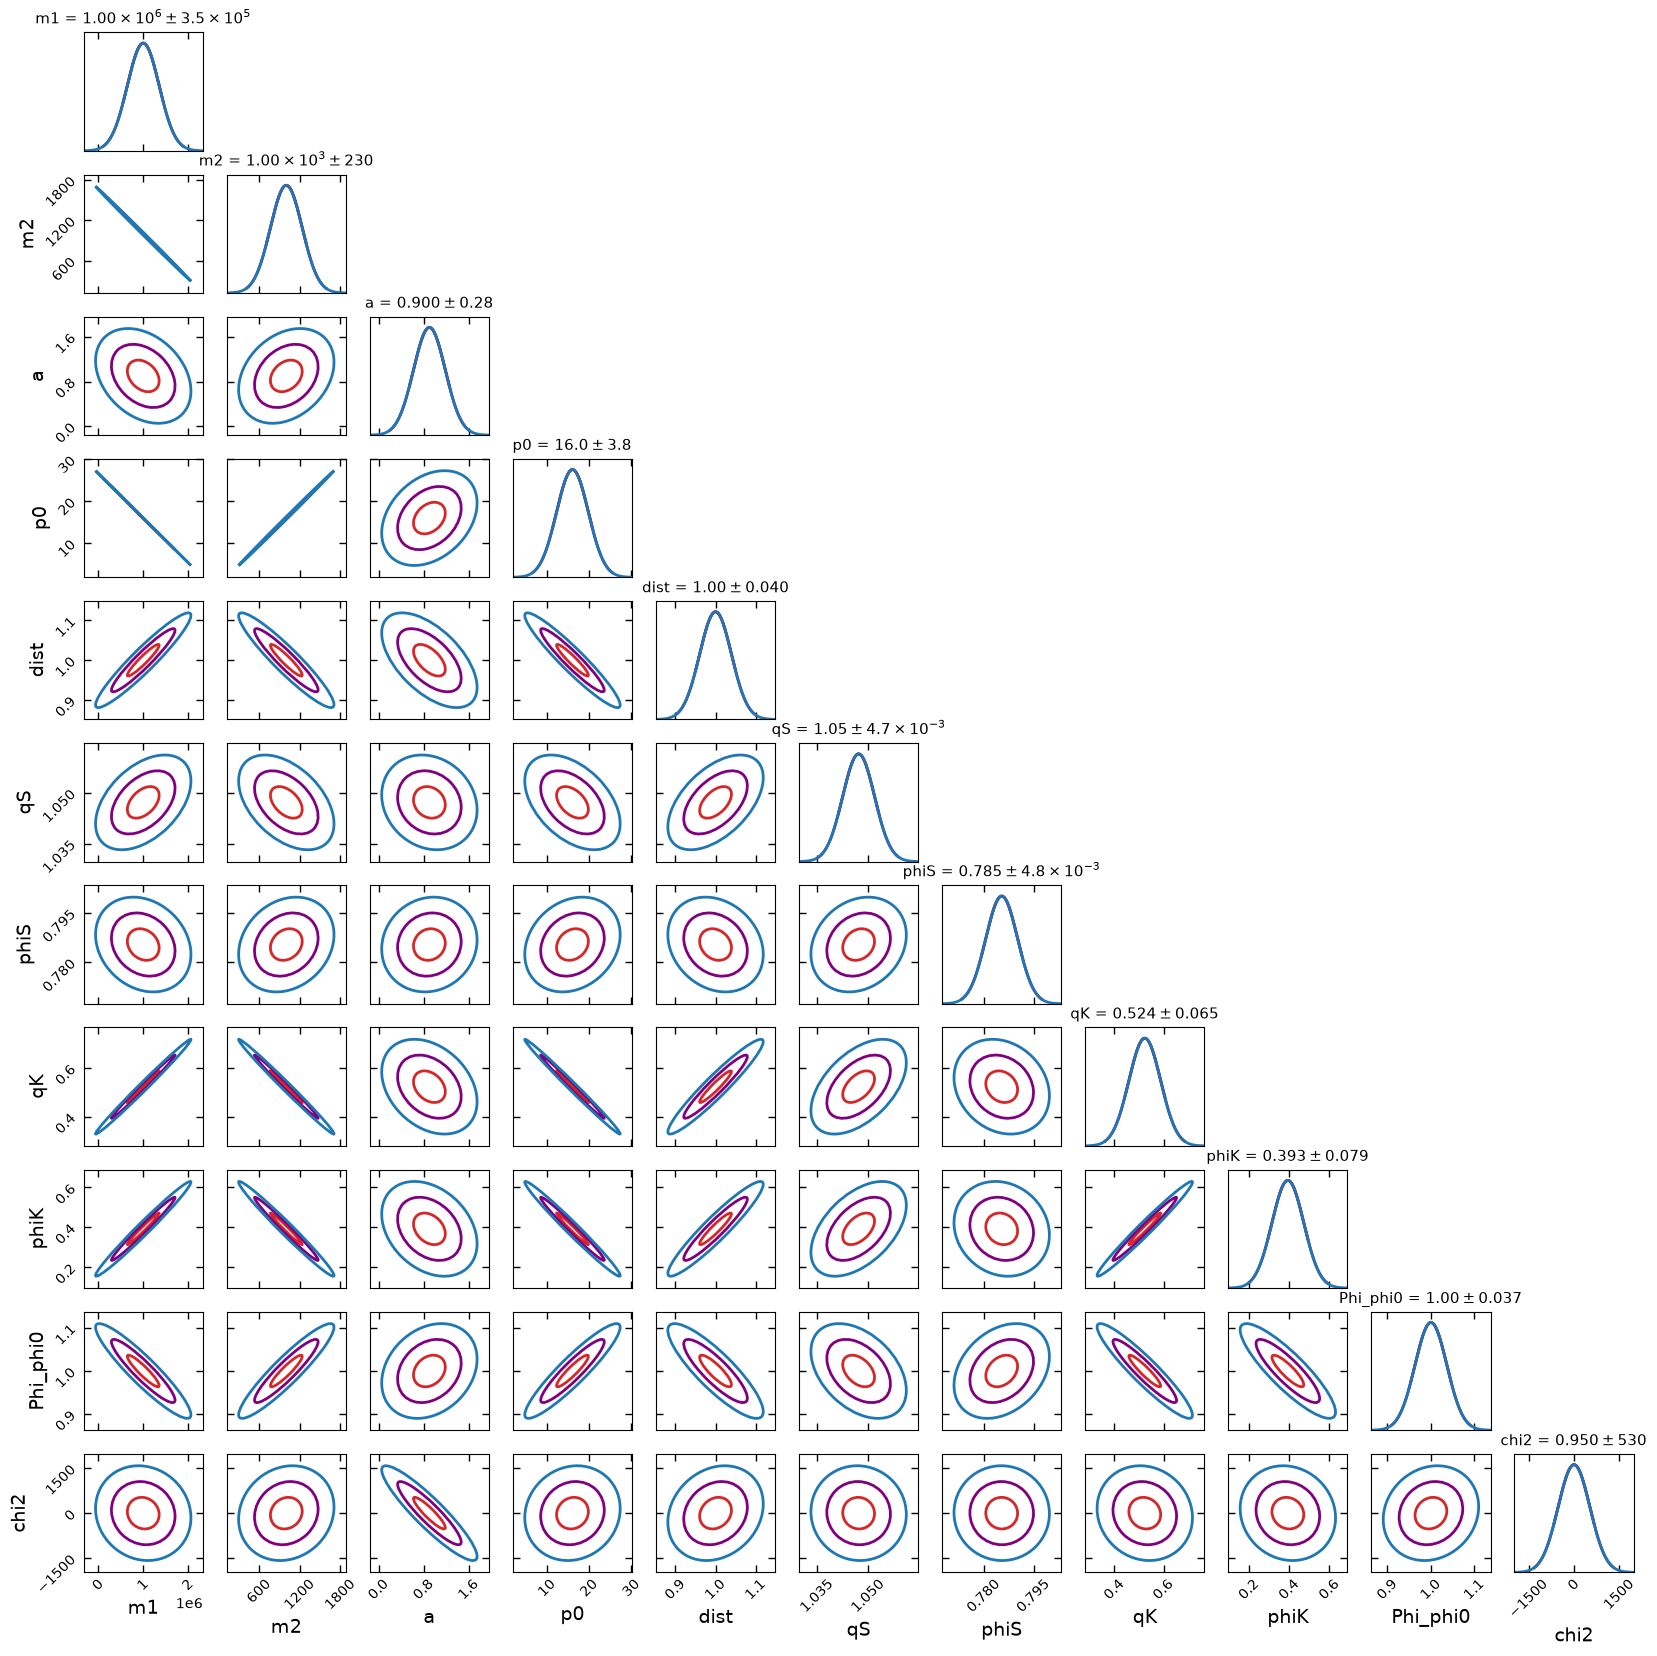

In [5]:
n = len(param_names)
fig, axs = plt.subplots(n, n, figsize=(20, 20))

for n_std, color in [(1, "tab:red"), (2, "purple"), (3, "tab:blue")]:
    plot_covariance_ellipses(
        covariance,
        param_names=param_names,
        wave_params=sef.wave_params,  # includes chi2
        fig=fig,
        axs=axs,
        ellipse_kwargs=dict(facecolor="none", edgecolor=color, lw=2, n_std=n_std),
        line_kwargs=dict(lw=2, color=color),
    )
plt.show()